# Human-Mammalian Brain - Subcortex spatial transcriptomics gene expression

In this notebook, we build on the our [previous investigation](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_spatial_slabs_and_taxonomy.html) into the cell level metadata, combining the metadata gene expressions for select genes that we extract from the released h5ad files.

You need to be connected to the internet to run this notebook and have run through the [getting started notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/getting_started.html).

In [1]:
import json
import geojson
from typing import List, Tuple, Optional

import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

from abc_atlas_access.abc_atlas_cache.abc_project_cache import AbcProjectCache
from abc_atlas_access.abc_atlas_cache.anndata_utils import get_gene_data

We will interact with the data using the **AbcProjectCache**. This cache object tracks which data has been downloaded and serves the path to the requested data on disk. For metadata, the cache can also directly serve a up a Pandas DataFrame. See the [``getting_started``](https://alleninstitute.github.io/abc_atlas_access/notebooks/getting_started.html) notebook for more details on using the cache including installing the cache if it has not already been.

**Change the download_base variable to where you would like to download the data in your system.**

In [2]:
download_base = Path('../../data/allen-brain-cell-atlas-staging')
abc_cache = AbcProjectCache.from_cache_dir(
    cache_dir=download_base,
    auth_required=True,
    s3_bucket='allen-brain-cell-atlas-staging'
)

abc_cache.current_manifest

'releases/20261130/manifest.json'

## Cell metadata

The Marmoset Subcortext spatial dataset has it's own h5ad files and associated cell metadata tables. These metadata contain the basic identifiers for each cell and forms the basis by which we will join all other cell level and associated data. In the [previous tutorial](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_spatial_slabs_and_taxonomy.html), we merged the cell metadata tables with their associated specimen metadatadata and then with the rotated coordinates we use to plot the cell locations.

Below we load the base metadata needed for extracting gene expressions. 

In [3]:
# Load the cell metadata and specimen metadata
# and join them together with the rotated coordinates.

cell_metadata = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='cell_metadata',
    dtype={"cell_label": str},
).set_index('cell_label')

specimen = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='specimen_metadata',
    dtype={"cell_label": str}
).set_index('brain_section_label')

cell_metadata = cell_metadata.join(specimen, on='brain_section_label', rsuffix='_specimen')

rotated_coordinates = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='rotated_coordinates',
    dtype={"cell_label": str}
).set_index('cell_label')
cell_metadata = cell_metadata.join(
    rotated_coordinates[['x_rotated_mm', 'y_rotated_mm']],
    on='cell_label'
)

del specimen
del rotated_coordinates

cell_metadata.head()

,brain_section_label,brain_section_barcode,x_experiment,y_experiment,segmentation_job_id,segmentation_method,cell_area,nucleus_area,n_nuclei_in_cell,total_counts,...,hemisphere,brain_division_label,brain_division_ordinal,donor_label,slab_plane_ordinal,slab_plane_label,slab_plane_order,slab_z_order,x_rotated_mm,y_rotated_mm
cell_label,,,,,,,,,,,,,,,,,,,,,
1382042951_aaondhbe-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4459.1006,4524.2420,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,89.81579,60.735157,1,339,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.651601,-5.898891
1382042951_aaoneabm-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4668.6323,4653.2130,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,105.98172,74.327190,1,762,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.508436,-6.098991
1382042951_aaonekin-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4593.0610,4594.6304,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.50813,74.598130,1,406,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.555394,-6.015698
1382042951_aaoofhco-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4529.3900,4348.2266,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,136.37189,72.475784,1,948,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.518584,-5.763877
1382042951_aaopgffc-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4524.6533,4382.6323,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.41782,78.391250,1,941,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.536286,-5.793757


### Geojson polygons

The dataset includes polygons outlining the subcortex, which can be plotted over rotated coordinates. These polygon annotations were manually drawn with best attempts made to be consistent across planes. These polygons are provided in [geojson](https://geojson.org/) format, and here we use the associated geojson python package to load the jsons for use in our visualization.

First though, we load the term set for these data.

In [4]:
value_sets = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='value_sets'
)
pred = value_sets['field'] == 'parcellation_term_symbol'
parcellation_terms = value_sets[pred].copy()
parcellation_terms.set_index('label', inplace=True)
parcellation_terms.head()

,table,field,description,order,external_identifier,parent_label,color_hex_triplet
label,,,,,,,
Subcortical,cell_anatomical_annotations,parcellation_term_symbol,Subcortical,1,subcortical,NaN,#000000
Basal ganglia and adjacent,cell_anatomical_annotations,parcellation_term_symbol,Basal ganglia and adjacent,2,basal_ganglia_and_adjacent,Subcortical,#BEBEBE
STR,cell_anatomical_annotations,parcellation_term_symbol,striatum,3,HOMBA:10333,Basal ganglia and adjacent,#cd86cc
GP,cell_anatomical_annotations,parcellation_term_symbol,globus pallidus,4,HOMBA:10342,Basal ganglia and adjacent,#7AE361
GPe,cell_anatomical_annotations,parcellation_term_symbol,external segment of globus pallidus,5,HOMBA:10343,Basal ganglia and adjacent,#53DB33


Below we define two functions that will be used in our plotting of the geojsons. The first takes in the data and a matplotlib axis object and plots the geojson data on the provided axis, extracting color and name information from the value/term set. The second loads the data based on the appropriate slab and species provided.

In [5]:
def plot_geo_data(geo_data: dict, ax: plt.Axes, terms=parcellation_terms):
    """Plot a geojson polygon over the input axis.

    Parameters
    ----------
    geo_data: dict
        Geojson formatted dictionary containing Polygons to plot.
    ax: matplotlib.pyplot.axis
        Axis object to plot the geojson data over.
    terms: pandas.DataFrame
        Term list containing the colors and orders for the parcellation, brain region terms. 
    """
    if geo_data is None:
        return None
    # If the geo_data is a FeatureCollection, we need to iterate over its
    # features and plot each one.
    if geo_data['type'] == 'FeatureCollection':
        for sub_data in geo_data['features']:
            plot_geo_data(sub_data, ax)
    elif geo_data['type'] == 'Feature':
        geometry_data = geo_data['geometry']
        name = geo_data['properties']['label']
        # color = terms.loc[name, 'color_hex_triplet'] # Get the color for this object from the term list.
        color = 'black' # Default color for the polygons.
        # If the geometry is a GeometryCollection, we need to iterate over its
        # geometries that make up the complete feature.
        if geometry_data['type'] == 'GeometryCollection':
            for idx, geometry in enumerate(geometry_data['geometries']):
                coords = np.array(list(geojson.coords(geometry)))
                # Only label the first geometry in the collection. Others
                # will be plotted without a label to avoid duplicate legend entries.
                if idx == 0:
                    ax.fill(coords[:, 0],
                            coords[:, 1],
                            edgecolor=color,
                            fill=False,
                            linewidth=3,
                            label=name)
                else:
                    ax.fill(coords[:, 0],
                            coords[:, 1],
                            edgecolor=color,
                            fill=False,
                            linewidth=3)
        else:
            coords = np.array(list(geojson.coords(geometry_data)))
            try:
                ax.fill(coords[:, 0],
                        coords[:, 1],
                        edgecolor=color,
                        fill=False,
                        linewidth=3,
                        label=name)
            except ValueError as e:
                import pdb; pdb.set_trace()
    else:
        print("unknown data", geo_data)

def get_polygons(slab_name: str) -> dict:
    """Load the geojson polygons for the specified slab and species.

    Parameters
    ----------
    slab_name: str
        Name of the slab to load.

    Returns
    -------
    dict
        Geojson formatted dictionary containing the polygons for the specified slab and species.
    """

    base_dir = 'HMBA-Subcortex-Xenium-Marmoset'

    file_path = abc_cache.get_file_path(
        directory=base_dir,
        file_name=slab_name,
        skip_hash_check=True,
        force_download=True
    )
    if not file_path.exists():
        return None

    with open(file_path) as jfile:
        data = json.load(jfile)
    
    return data

## Gene expression data

Now we can extract expression for specific genes from the h5ad files and pair it with our gene metadata. In general, we can use the function `get_gene_data` to extract the expression of specific genes for all the cells in a given dataset or a subset of cells.. For more details on using this convenience function, see the [Accessing 10x RNA-seq gene expression data](https://alleninstitute.github.io/abc_atlas_access/notebooks/general_accessing_10x_snRNASeq_tutorial.html) tutorial notebook.

For this tutorial we will use precomputed tables of the expression for specific genes to compare expression both spatially and by the taxonomy.

To use the gene expression data, we first load the set of genes for the subcortex data.

In [6]:
genes = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='gene',
).set_index('gene_identifier')
genes.head()

,gene_symbol,description,molecular_type
gene_identifier,,,
NCBIGene:100393956,ABI3BP,ABI family member 3 binding protein,protein_coding
NCBIGene:100388523,ABL2,"ABL proto-oncogene 2, non-receptor tyrosine ki...",protein_coding
NCBIGene:100389219,ABLIM1,actin binding LIM protein 1,protein_coding
NCBIGene:100400228,ACAP2,"ArfGAP with coiled-coil, ankyrin repeat and PH...",protein_coding
NCBIGene:100392257,ACHE,acetylcholinesterase (Cartwright blood group),protein_coding


We define a set of genes to load via their symbol. We reuse the smaller overlapping subset of genes we used in the previous [10X gene expression notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_10X_snRNASeq_tutorial.html).

In [7]:
gene_names = ['AQP4', 'DRD1', 'DRD2', 'SLC17A6']

In the cell below, we show how to use the `get_gene_data` function to extract the expression of specific genes from the h5ad metadata. In the commented code, we combine our abc_cache object, cell metadata, gene metadata, and gene symbols we would like select in our `get_gene_data` function that downloads and extracts gene expression data from the h5ad file. Note that this function is an example and should not be used on small systems to extract a large number of genes for all cells at once. For a small subset of cells, it can be used to pull expression data from the h5ad file for all genes.

The methods below will pull data from the natural-log, batch-normalized data. These are data where the raw counts are normalized by scaling all cells within each section (per brain_section_barcode) to the mean total counts of a reference cell population, in this case the counts in the cell type Group, Astrocyte. This is done because their population count correlates with the total neuron count across sections and they are distributed across diverse anatomical regions using the following qsudo-code:

```
section_factor = global_reference_cells_mean / section_reference_cells_mean
batch_normalized_counts = section_factor * raw_counts
```

For this tutorial we will skip using these functions and instead use a pre-computed gene expression to save time. For specifics on how to use the below functions see [this tutorial](https://alleninstitute.github.io/abc_atlas_access/notebooks/general_accessing_10x_snRNASeq_tutorial.html).

In [ ]:
"""
gene_data = get_gene_data(
    abc_atlas_cache=abc_cache,
    all_cells=cell_metadata,
    all_genes=genes,
    selected_genes=gene_names,
    data_type='ln'
)"""

loading file: Xenium-CJ23.56.004-Subcortex-batch-normalized
 - time taken:  142.898521
total time taken: 142.900045
	total cells: 5580065 processed cells: 5580065


We load the precomputed gene expressions for each species below instead of running the processing. Note that the Human and Marmoset data contain all 4 of the genes we requested, however AQP4 is not in the Macaque data.

In [9]:
gene_data = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='example_gene_expression',
).set_index('cell_label')
gene_data.head()

KeyError: 'File example_gene_expression not found in directory HMBA-Subcortex-Xenium-Marmoset.'

In [10]:
gene_data.head()

gene_symbol,AQP4,DRD1,DRD2,SLC17A6
cell_label,,,,
1382042951_aaondhbe-1-20250227,0.000000,0.926574,0.000000,0.0
1382042951_aaoneabm-1-20250227,0.000000,0.000000,0.566971,0.0
1382042951_aaonekin-1-20250227,0.566971,0.566971,0.000000,0.0
1382042951_aaoofhco-1-20250227,0.000000,0.566971,0.000000,0.0
1382042951_aaopgffc-1-20250227,0.000000,0.000000,0.000000,0.0


Now that we've loaded our expression matrix tables, indexed by cell_label, we can merge them into our cell metadata tables.

In [11]:
cell_metadata_with_genes = cell_metadata.join(gene_data, on='cell_label')

# clean up memory
del gene_data

### Geojson polygons

The dataset includes polygons outlining the subcortex, which can be plotted over rotated coordinates. These polygon annotations were manually drawn with best attempts made to be consistent across planes. These polygons are provided in [geojson](https://geojson.org/) format, and here we use the associated geojson python package to load the jsons for use in our visualization.

First though, we load the term set for these data.

In [12]:
value_sets = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-Xenium-Marmoset',
    file_name='value_sets'
).set_index('label')
pred = value_sets['field'] == 'parcellation_term_symbol'
parcellation_terms = value_sets[pred].copy()
parcellation_terms.head()

,table,field,description,order,external_identifier,parent_label,color_hex_triplet
label,,,,,,,
Subcortical,cell_anatomical_annotations,parcellation_term_symbol,Subcortical,1,subcortical,NaN,#000000
Basal ganglia and adjacent,cell_anatomical_annotations,parcellation_term_symbol,Basal ganglia and adjacent,2,basal_ganglia_and_adjacent,Subcortical,#BEBEBE
STR,cell_anatomical_annotations,parcellation_term_symbol,striatum,3,HOMBA:10333,Basal ganglia and adjacent,#cd86cc
GP,cell_anatomical_annotations,parcellation_term_symbol,globus pallidus,4,HOMBA:10342,Basal ganglia and adjacent,#7AE361
GPe,cell_anatomical_annotations,parcellation_term_symbol,external segment of globus pallidus,5,HOMBA:10343,Basal ganglia and adjacent,#53DB33


Below we define two functions that will be used in our plotting of the geojsons. The first takes in the data and a matplotlib axis object and plots the geojson data on the provided axis, extracting color and name information from the value/term set. The second loads the data based on the appropriate slab and species provided.

In [13]:
def plot_geo_data(geo_data: dict, ax: plt.Axes, terms=parcellation_terms):
    """Plot a geojson polygon over the input axis.

    Parameters
    ----------
    geo_data: dict
        Geojson formatted dictionary containing Polygons to plot.
    ax: matplotlib.pyplot.axis
        Axis object to plot the geojson data over.
    terms: pandas.DataFrame
        Term list containing the colors and orders for the parcellation, brain region terms. 
    """
    if geo_data is None:
        return None
    # If the geo_data is a FeatureCollection, we need to iterate over its
    # features and plot each one.
    if geo_data['type'] == 'FeatureCollection':
        for sub_data in geo_data['features']:
            plot_geo_data(sub_data, ax)
    elif geo_data['type'] == 'Feature':
        geometry_data = geo_data['geometry']
        name = geo_data['properties']['label']
        # color = terms.loc[name, 'color_hex_triplet'] # Get the color for this object from the term list.
        color = 'black' # Default color for the polygons.
        # If the geometry is a GeometryCollection, we need to iterate over its
        # geometries that make up the complete feature.
        if geometry_data['type'] == 'GeometryCollection':
            for idx, geometry in enumerate(geometry_data['geometries']):
                coords = np.array(list(geojson.coords(geometry)))
                # Only label the first geometry in the collection. Others
                # will be plotted without a label to avoid duplicate legend entries.
                if idx == 0:
                    ax.fill(coords[:, 0],
                            coords[:, 1],
                            edgecolor=color,
                            fill=False,
                            linewidth=3,
                            label=name)
                else:
                    ax.fill(coords[:, 0],
                            coords[:, 1],
                            edgecolor=color,
                            fill=False,
                            linewidth=3)
        else:
            coords = np.array(list(geojson.coords(geometry_data)))
            try:
                ax.fill(coords[:, 0],
                        coords[:, 1],
                        edgecolor=color,
                        fill=False,
                        linewidth=3,
                        label=name)
            except ValueError as e:
                import pdb; pdb.set_trace()
    else:
        print("unknown data", geo_data)

def get_polygons(slab_name: str) -> dict:
    """Load the geojson polygons for the specified slab and species.

    Parameters
    ----------
    slab_name: str
        Name of the slab to load.

    Returns
    -------
    dict
        Geojson formatted dictionary containing the polygons for the specified slab and species.
    """

    base_dir = 'HMBA-Subcortex-Xenium-Marmoset'

    file_path = abc_cache.get_file_path(
        directory=base_dir,
        file_name=slab_name,
        skip_hash_check=True,
        force_download=True
    )
    if not file_path.exists():
        return None

    with open(file_path) as jfile:
        data = json.load(jfile)
    
    return data

### Plotting the Slabs

We define a helper function *plot_slabs* to visualize the cells for a specified set of brain sections either by colorized metadata or gene expression. This function can be used to plot individual brain sections as well.

In [14]:
def plot_slabs(
    df: pd.DataFrame,
    feature: str,
    slab_list: List[str],
    cmap: Optional[plt.Colormap] = None,
    fig_width: float = 40,
    fig_height: float = 8,
    plot_polygons: bool = False,
    point_size: float = 1.0,
    fix_bounds: bool = False
) -> Tuple[plt.Figure, np.ndarray]:
    """Plot spatial transcriptomics data.

    Parameters
    ----------
    df: pandas.DataFrame
        cell metadata data frame with x,y locations to plot.
    feature: str
        Expression value or color column to plot.
    slab_list: List[str]
        List of slab_plane ids to plot.
    cmap: matplotlib.colors.Colormap
        Colormap for expression features.
    fig_width: int
        Width of the plotted figure.
    fig_height: int
        Height of the plotted figure.
    plot_polygons: bool
        Overplot geojson polygons. Note that these are note available for human
        and this should be set to False.
    point_size: float
        Size of the points to plot.
    fix_bounds: bool
        If True, fix the x and y bounds across all slabs to be the same.
    """
    if isinstance(slab_list, str):
        slab_list = [slab_list]

    fig, ax = plt.subplots(1, len(slab_list))
    fig.set_size_inches(fig_width, fig_height)

    if len(slab_list) == 1:
        ax = [ax]

    if 'x' in df.columns:
        x_col = 'x'
    elif 'x_rotated_mm' in df.columns:
        x_col = 'x_rotated_mm'
    if 'y' in df.columns:
        y_col = 'y'
    elif 'y_rotated_mm' in df.columns:
        y_col = 'y_rotated_mm'

    if fix_bounds:
        x_min = df[x_col].min() * 0.8
        x_max = df[x_col].max() * 1.2
        y_min = df[y_col].min() * 0.8
        y_max = df[y_col].max() * 1.2

    for idx, slab in enumerate(slab_list):

        if 'slab_plane_label' in df.columns:
            filtered = df[df['slab_plane_label'] == slab]
        elif 'brain_section_label' in df.columns:
            filtered = df[df['brain_section_label'] == slab]
        
        xx = filtered[x_col]
        yy = filtered[y_col]
        vv = filtered[feature]
        
        if cmap is not None:
            ax[idx].scatter(xx, yy, s=point_size, c=vv, marker='.', cmap=cmap)
        else:
            
            ax[idx].scatter(xx, yy, s=point_size, c=vv, marker=".")

        if plot_polygons:
            plot_geo_data(get_polygons(slab), ax[idx])
            
        ax[idx].axis('equal')
        if fix_bounds:
            ax[idx].set_ylim(y_min, y_max)
            ax[idx].set_xlim(x_min, x_max)
        ylim = ax[idx].get_ylim()
        ax[idx].set_xticks([])
        ax[idx].set_yticks([])
        
        ax[idx].set_title(slab)
        ax[idx].legend(loc=0)
        
    plt.subplots_adjust(wspace=0.01, hspace=0.01)
    return fig, ax

Below we plot the spatial expression of our genes across the different species. We select a minium expression value of which effectively masks out zero expression cells from the plots, showing a bit more contrast. Feel free to experiment with different vmin and vmax values in investigate the gene expressions more in depth.

CJ23.56.004.CX.42.Plane.05.geojson: 100%|██████████| 938/938 [00:00<00:00, 12.1kMB/s]
CJ23.56.004.CX.42.Plane.13.geojson: 100%|██████████| 1.07k/1.07k [00:00<00:00, 22.1kMB/s]
CJ23.56.004.CX.43.Plane.05.geojson: 100%|██████████| 1.12k/1.12k [00:00<00:00, 7.66kMB/s]
CJ23.56.004.CX.43.Plane.15.geojson: 100%|██████████| 1.44k/1.44k [00:00<00:00, 28.8kMB/s]
CJ23.56.004.CX.44.Plane.03.geojson: 100%|██████████| 1.57k/1.57k [00:00<00:00, 39.3kMB/s]


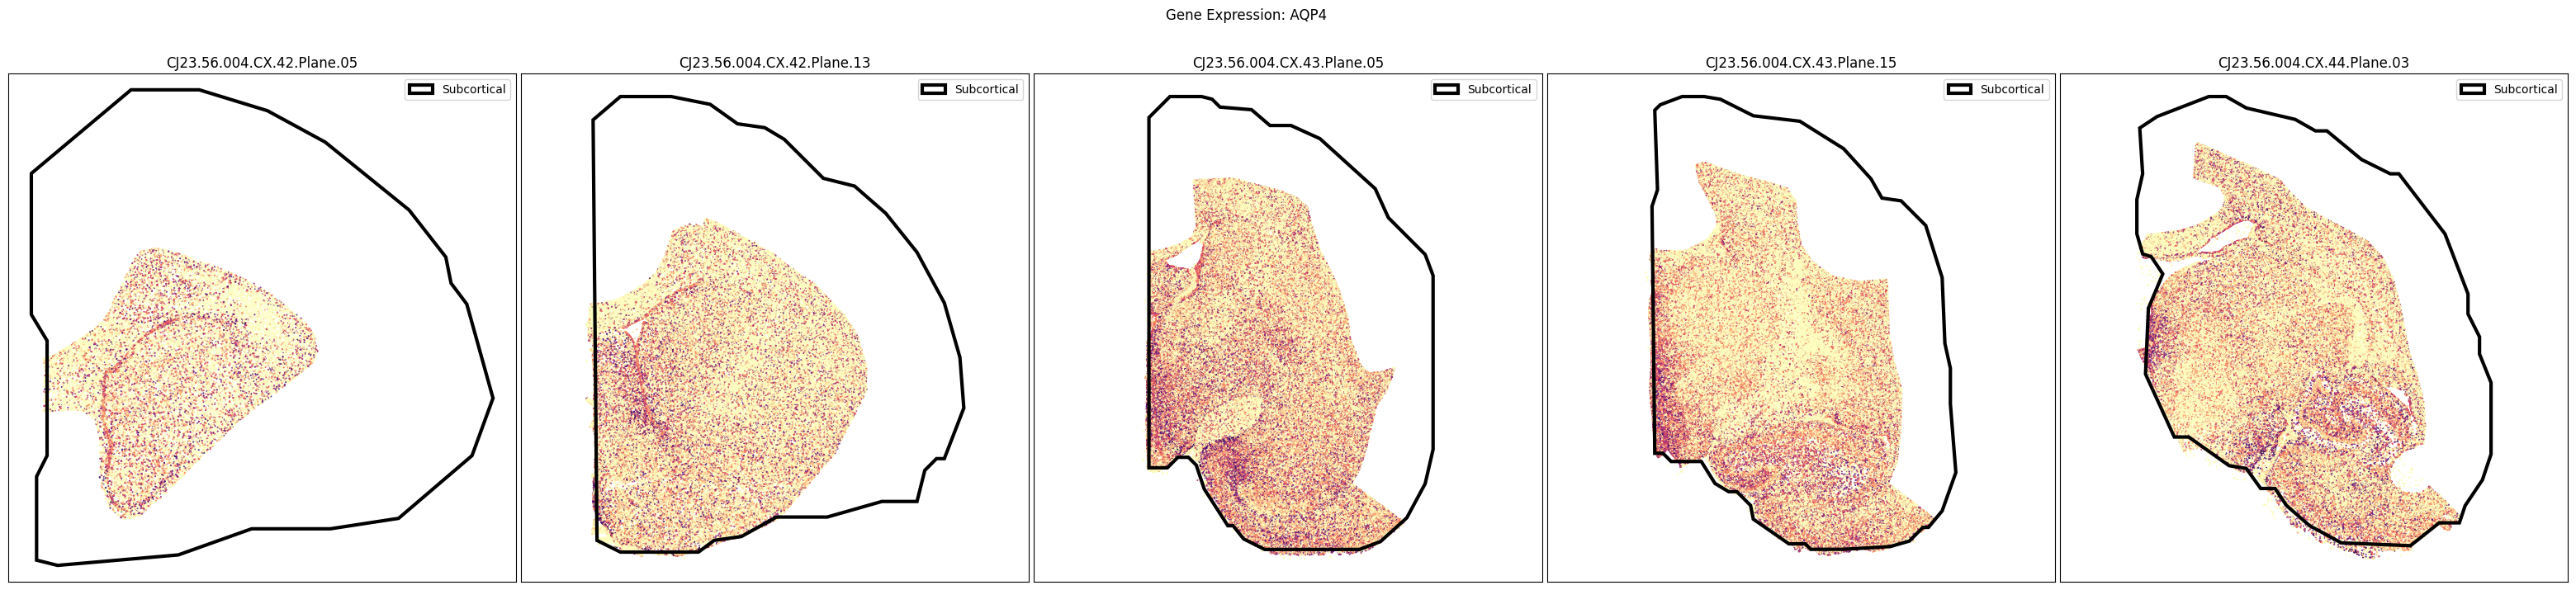

CJ23.56.004.CX.42.Plane.05.geojson: 100%|██████████| 938/938 [00:00<00:00, 14.9kMB/s]
CJ23.56.004.CX.42.Plane.13.geojson: 100%|██████████| 1.07k/1.07k [00:00<00:00, 23.4kMB/s]
CJ23.56.004.CX.43.Plane.05.geojson: 100%|██████████| 1.12k/1.12k [00:00<00:00, 20.5kMB/s]
CJ23.56.004.CX.43.Plane.15.geojson: 100%|██████████| 1.44k/1.44k [00:00<00:00, 36.9kMB/s]
CJ23.56.004.CX.44.Plane.03.geojson: 100%|██████████| 1.57k/1.57k [00:00<00:00, 31.1kMB/s]


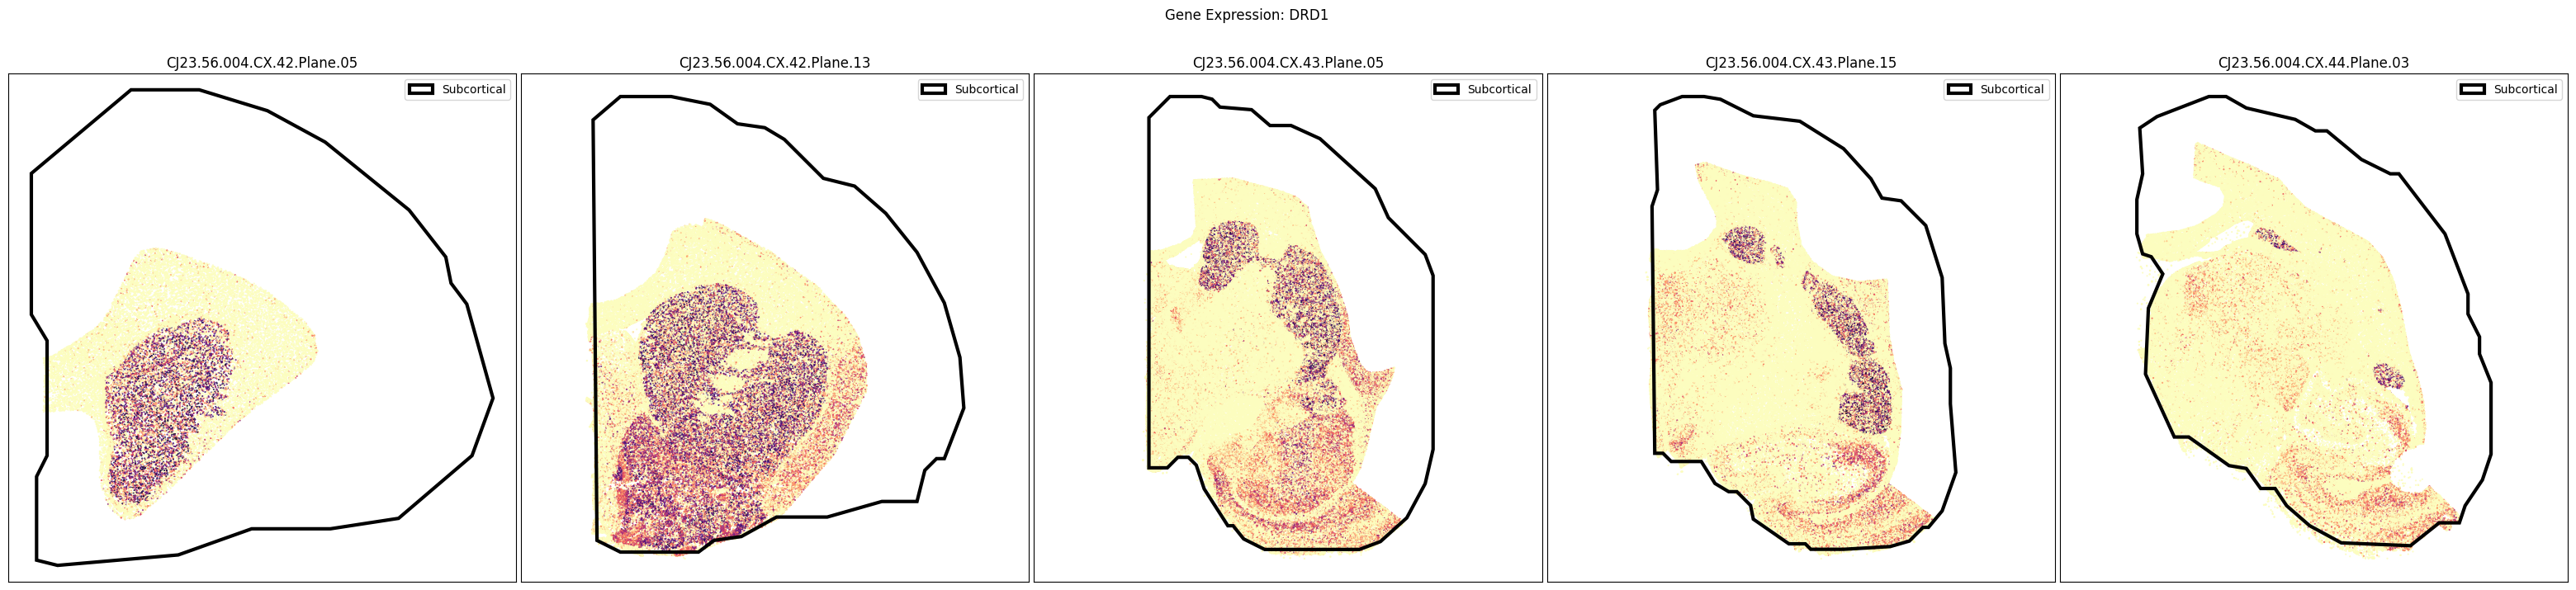

CJ23.56.004.CX.42.Plane.05.geojson: 100%|██████████| 938/938 [00:00<00:00, 16.2kMB/s]
CJ23.56.004.CX.42.Plane.13.geojson: 100%|██████████| 1.07k/1.07k [00:00<00:00, 23.5kMB/s]
CJ23.56.004.CX.43.Plane.05.geojson: 100%|██████████| 1.12k/1.12k [00:00<00:00, 15.8kMB/s]
CJ23.56.004.CX.43.Plane.15.geojson: 100%|██████████| 1.44k/1.44k [00:00<00:00, 29.9kMB/s]
CJ23.56.004.CX.44.Plane.03.geojson: 100%|██████████| 1.57k/1.57k [00:00<00:00, 43.7kMB/s]


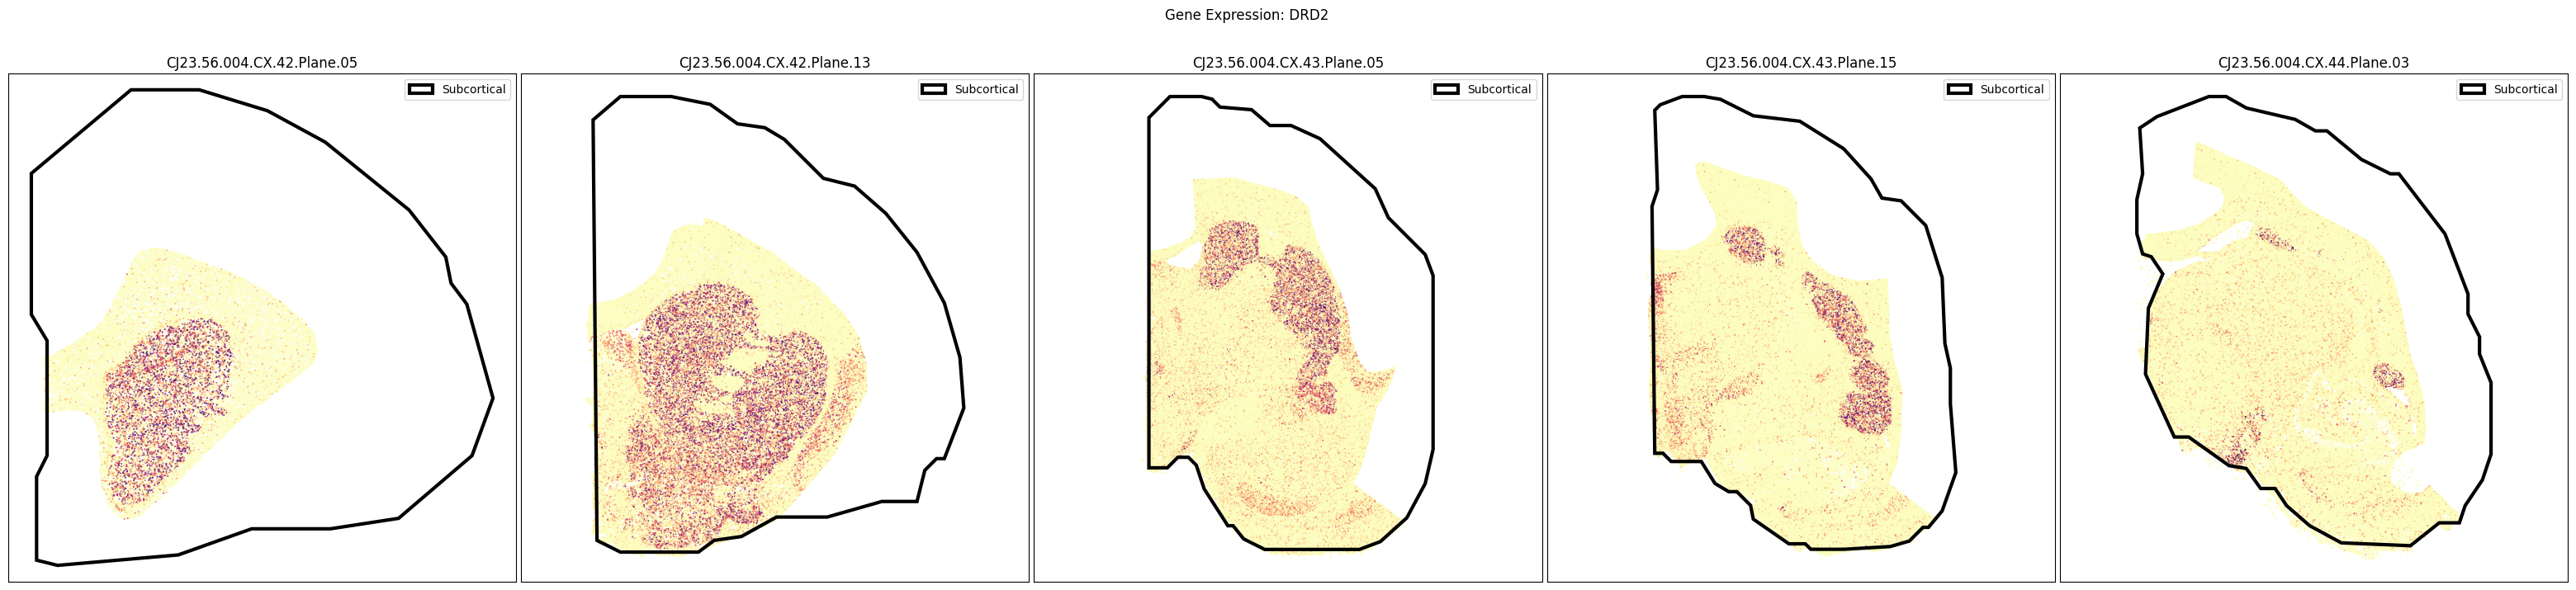

CJ23.56.004.CX.42.Plane.05.geojson: 100%|██████████| 938/938 [00:00<00:00, 17.6kMB/s]
CJ23.56.004.CX.42.Plane.13.geojson: 100%|██████████| 1.07k/1.07k [00:00<00:00, 26.5kMB/s]
CJ23.56.004.CX.43.Plane.05.geojson: 100%|██████████| 1.12k/1.12k [00:00<00:00, 14.7kMB/s]
CJ23.56.004.CX.43.Plane.15.geojson: 100%|██████████| 1.44k/1.44k [00:00<00:00, 25.7kMB/s]
CJ23.56.004.CX.44.Plane.03.geojson: 100%|██████████| 1.57k/1.57k [00:00<00:00, 31.9kMB/s]


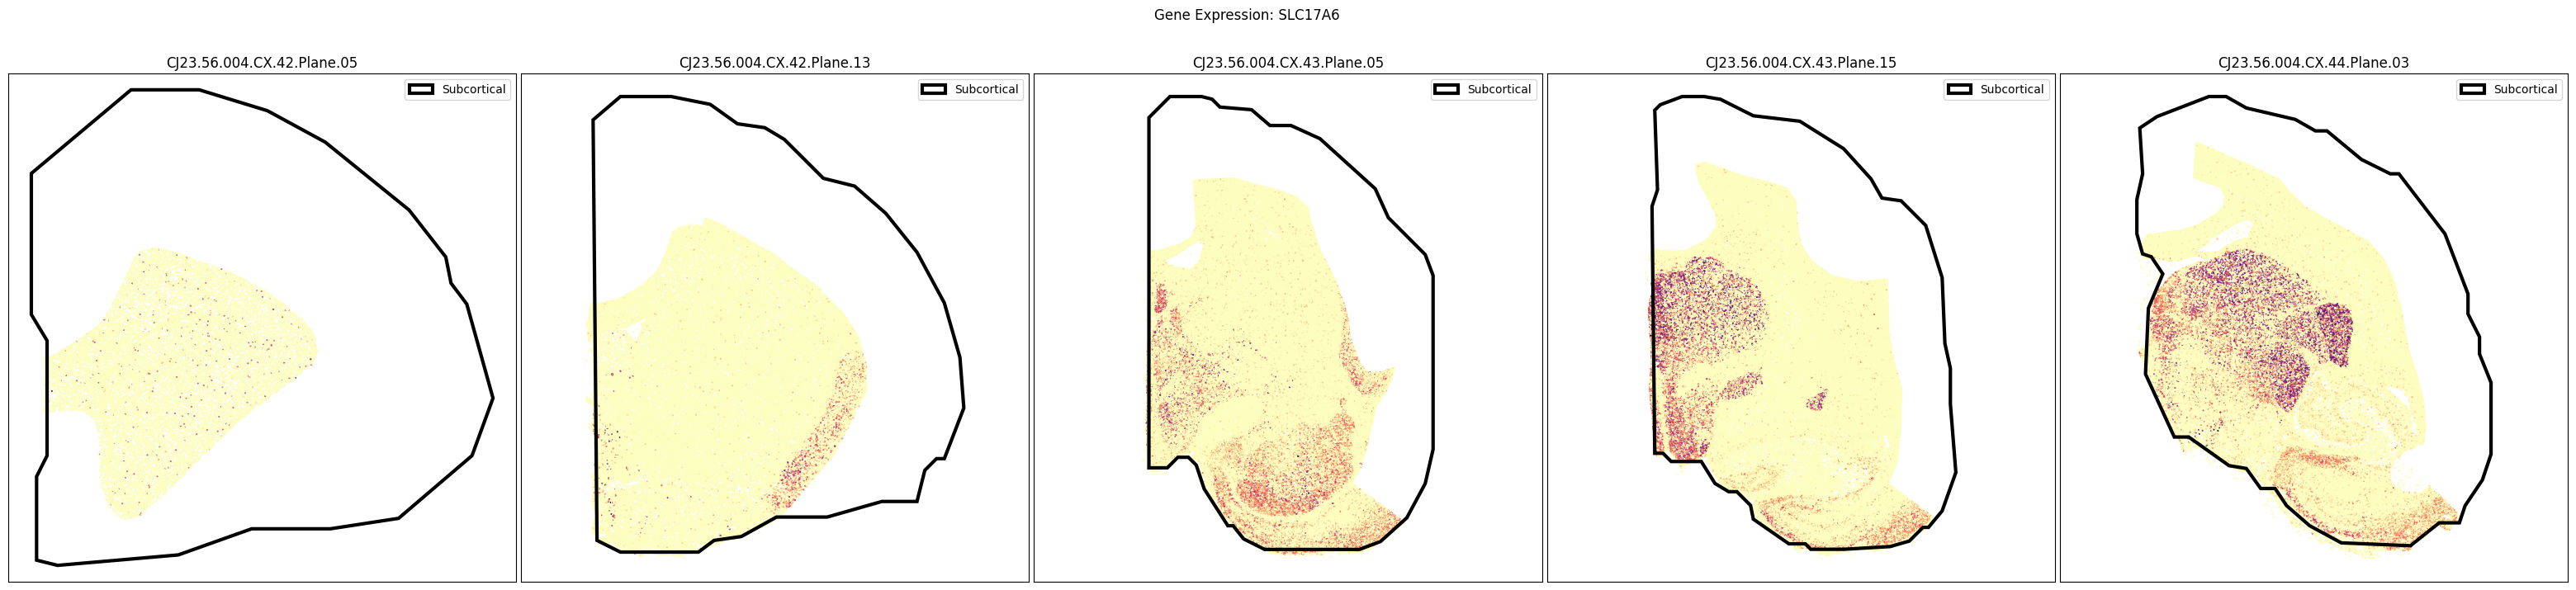

In [15]:
gene_names = cell_metadata_with_genes.columns[
    cell_metadata_with_genes.columns.isin(gene_names)
].to_numpy()
slab_list = [
    'CJ23.56.004.CX.42.Plane.05', 'CJ23.56.004.CX.42.Plane.13', 'CJ23.56.004.CX.43.Plane.05',
    'CJ23.56.004.CX.43.Plane.15', 'CJ23.56.004.CX.44.Plane.03'
]
for gene_symbol in gene_names:
    fig, ax = plot_slabs(
        cell_metadata_with_genes,
        gene_symbol,
        slab_list,
        cmap=plt.cm.magma_r,
        plot_polygons=True,
    )
    fig.suptitle(f'Gene Expression: {gene_symbol}')
    plt.show()

## Taxonomy mapping

Finally, let's load the taxonomy information so that we can plot gene expression versus various taxons in a heatmap for each species. Below, we load and merge all the information we need to plot cell colors and taxonomy as done in previous [HMBA-Subcortex tutorial](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_clustering_analysis_and_annotation.html).

Note that the taxonomy mapping also contains neurotransmitter and dominant brain region locations.

Below we load the subcortex taxonomy. For more details on this taxonomy see the [notebook here](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_clustering_analysis_and_annotation.html).

In [16]:
cell_to_cluster_membership = abc_cache.get_metadata_dataframe(
    'HMBA-Subcortex-Xenium-Marmoset', 'cell_to_cluster_membership'
).set_index('cell_label')

cluster = abc_cache.get_metadata_dataframe(
    'HMBA-Subcortex-taxonomy', 'cluster'
).set_index('label')
cluster_annotation_term = abc_cache.get_metadata_dataframe(
    'HMBA-Subcortex-taxonomy', 'cluster_annotation_term'
).set_index('label')

cluster_annotation_term_set = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy',
    file_name='cluster_annotation_term_set'
).set_index('label')

cluster_to_cluster_annotation_membership = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy',
    file_name='cluster_to_cluster_annotation_membership'
).set_index('cluster_annotation_term_label')

membership_with_cluster_info = cluster_to_cluster_annotation_membership.join(
    cluster.reset_index().set_index('cluster_alias')[['number_of_cells']],
    on='cluster_alias'
)

membership_with_cluster_info = membership_with_cluster_info.join(cluster_annotation_term, rsuffix='_anno_term').reset_index()

membership_groupby = membership_with_cluster_info.groupby(
    ['cluster_alias', 'cluster_annotation_term_set_name']
)

cluster_details = membership_groupby['cluster_annotation_term_name'].first().unstack()
cluster_order = membership_groupby['term_order'].first().unstack()

cluster_colors = membership_groupby['color_hex_triplet'].first().unstack()
cluster_colors = cluster_colors[cluster_annotation_term_set['name']]

cluster_to_dominant_region = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy',
    file_name='cluster_to_dominant_region',
).set_index('cluster_alias')
cluster_to_neurotransmitter = abc_cache.get_metadata_dataframe(
    directory='HMBA-Subcortex-taxonomy',
    file_name='cluster_to_neurotransmitter',
).set_index('cluster_alias')

cell_metadata_with_genes = cell_metadata_with_genes.join(cell_to_cluster_membership)
cell_metadata_with_genes = cell_metadata_with_genes.join(cluster_details, on='cluster_alias')
cell_metadata_with_genes = cell_metadata_with_genes.join(cluster_colors, on='cluster_alias', rsuffix='_color')
cell_metadata_with_genes = cell_metadata_with_genes.join(cluster_order, on='cluster_alias', rsuffix='_order')
cell_metadata_with_genes = cell_metadata_with_genes.join(cluster_to_dominant_region, on='cluster_alias', rsuffix='_region')
cell_metadata_with_genes = cell_metadata_with_genes.join(cluster_to_neurotransmitter, on='cluster_alias', rsuffix='_neurotransmitter')

del cell_to_cluster_membership

cell_metadata.head()

,brain_section_label,brain_section_barcode,x_experiment,y_experiment,segmentation_job_id,segmentation_method,cell_area,nucleus_area,n_nuclei_in_cell,total_counts,...,hemisphere,brain_division_label,brain_division_ordinal,donor_label,slab_plane_ordinal,slab_plane_label,slab_plane_order,slab_z_order,x_rotated_mm,y_rotated_mm
cell_label,,,,,,,,,,,,,,,,,,,,,
1382042951_aaondhbe-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4459.1006,4524.2420,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,89.81579,60.735157,1,339,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.651601,-5.898891
1382042951_aaoneabm-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4668.6323,4653.2130,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,105.98172,74.327190,1,762,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.508436,-6.098991
1382042951_aaonekin-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4593.0610,4594.6304,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.50813,74.598130,1,406,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.555394,-6.015698
1382042951_aaoofhco-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4529.3900,4348.2266,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,136.37189,72.475784,1,948,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.518584,-5.763877
1382042951_aaopgffc-1-20250227,CJ23.56.004.CX.42.01.06,1382042951,4524.6533,4382.6323,10X cell segmentation kit - default,Segmented by boundary stain (ATP1A1+CD45+E-Cad...,129.41782,78.391250,1,941,...,right,CJ23.56.004.CX,1,CJ23.56.004,1,CJ23.56.004.CX.42.Plane.01,14201,1,3.536286,-5.793757


In [17]:
def extract_value_set(
    cell_metadata_df: pd.DataFrame,
    input_value_set: pd.DataFrame,
    input_value_set_label: str,
    value_set_label: str=None
):
    """Add color and order columns to the cell metadata dataframe based on the input
    value set.

    Columns are added as {input_value_set_label}_color and {input_value_set_label}_order.

    Parameters
    ----------
    cell_metadata_df : pd.DataFrame
        DataFrame containing cell metadata.
    input_value_set : pd.DataFrame
        DataFrame containing the value set information.
    input_value_set_label : str
        The the column name to extract color and order information for. will be added to the cell metadata.
    """
    if value_set_label is None:
        value_set_label = input_value_set_label
    cell_metadata_df[f'{input_value_set_label}_color'] = input_value_set[
        input_value_set['field'] == value_set_label
    ].loc[cell_metadata_df[input_value_set_label]]['color_hex_triplet'].values
    cell_metadata_df[f'{input_value_set_label}_order'] = input_value_set[
        input_value_set['field'] == value_set_label
    ].loc[cell_metadata_df[input_value_set_label]]['order'].values

extract_value_set(cell_metadata_with_genes, value_sets, 'Cluster_neurotransmitter', 'neurotransmitter')
extract_value_set(cell_metadata_with_genes, value_sets, 'Group_neurotransmitter', 'neurotransmitter')
extract_value_set(cell_metadata_with_genes, value_sets, 'Cluster_dominant_region', 'dominant_region')
extract_value_set(cell_metadata_with_genes, value_sets, 'Group_dominant_region', 'dominant_region')

### Plotting heatmap expression data.

We define a helper functions *aggregate_by_metadata* to compute the average expression for a given category. Note that this is a simple wrapper of the Pandas GroupBy functionality. Other summary statistics beyond just the `mean` are listed here: https://pandas.pydata.org/docs/reference/groupby.html#dataframegroupby-computations-descriptive-stats

We also define a function to plot the resultant averaged data in a heatmap.

In [18]:
def aggregate_by_metadata(df: pd.DataFrame, gnames: List[str], value: str, sort: bool = False) -> pd.DataFrame:
    """Aggregate gene expression data by metadata.

    Parameters
    ----------
    df: pandas.DataFrame
        DataFrame containing gene expression and metadata.
    gnames: List[str]
        List of gene names to aggregate.
    value: str
    sort: bool
        Metadata column to group by.
        If True, sort the output by the first gene in gnames.

    Returns
    -------
    pandas.DataFrame
        DataFrame with aggregated gene expression values.
    """
    grouped = df.groupby(value)[gnames].mean()
    if sort:
        grouped = grouped.sort_values(by=gnames[0], ascending=False)
    return grouped


def plot_heatmap(
        df: pd.DataFrame,
        fig_width: int = 8,
        fig_height: int = 4,
        cmap: mpl.colormaps = plt.cm.magma,
        vmax: Optional[float] = None,
        unit: str = '[ln(batch-normalized + 1)]'
    ) -> Tuple[plt.Figure, plt.Axes]:
    """Plot a heatmap from a DataFrame.

    Parameters
    ----------
    df: pandas.DataFrame
        DataFrame to plot as a heatmap.
    fig_width: int
        Width of the figure.
    fig_height: int
        Height of the figure.
    cmap: matplotlib.colors.Colormap
        Colormap to use for the heatmap.

    Returns
    -------
    fig: matplotlib.pyplot.Figure
        Figure object containing the heatmap.
    ax: matplotlib.pyplot.Axes
        Axes object containing the heatmap.
    """

    arr = df.to_numpy().astype('float')

    vmin = arr.min()
    vmax = arr.max()
    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
    sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
    cmap = sm.get_cmap()

    fig, ax = plt.subplots()
    fig.set_size_inches(fig_width, fig_height)

    ax.imshow(arr, cmap=cmap, aspect='auto')
    xlabs = df.columns.values
    ylabs = df.index.values

    ax.set_xticks(range(len(xlabs)))
    ax.set_xticklabels(xlabs)

    ax.set_yticks(range(len(ylabs)))
    ax.set_yticklabels(ylabs)

    cbar = fig.colorbar(sm, ax=ax, orientation='vertical', fraction=0.1, pad=0.01)
    cbar.set_label(unit)

    return fig, ax

### Visualize gene expression for selected genes by the HMBA-Subcortex taxonomy.

Below we average the expression of our selected genes across taxons from the HMBA-Subcortex taxonomy. We show the expression for taxons at the class level for each species. For a side by side comparison of gene expression heatmaps for each species, see the [HMBA 10X gene expression tutorial](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_10X_snRNASeq_tutorial.html).

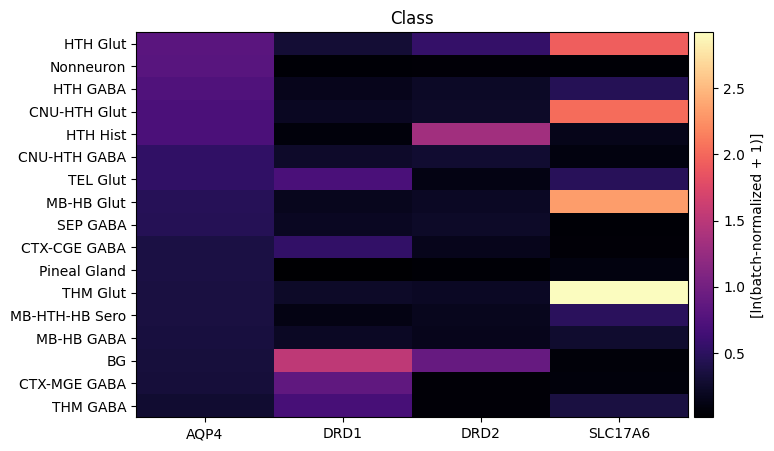

In [19]:
gene_names = cell_metadata_with_genes.columns[
    cell_metadata_with_genes.columns.isin(gene_names)
].to_numpy()
agg = aggregate_by_metadata(cell_metadata_with_genes, gene_names, 'Class', sort=True)
plot_heatmap(agg, 8, 5)
plt.title('Class')
plt.show()

### Visualize gene expression for selected genes by dominant region.

Below we average the expression of our selected genes across the different dominant regions that each cell is uniquely assigned to. We compute these expressions for each species individually.

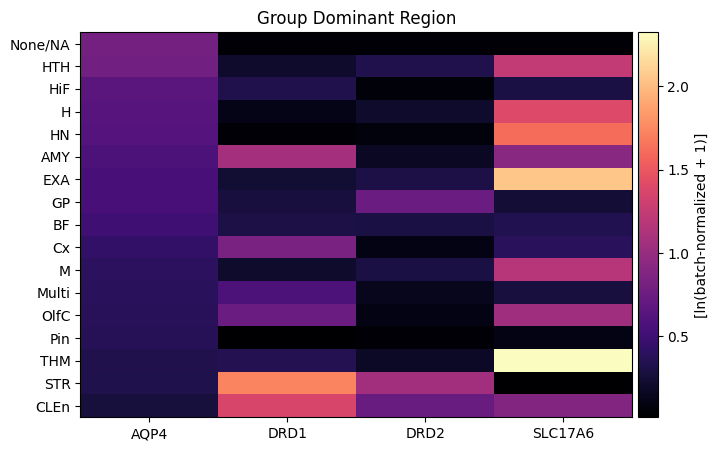

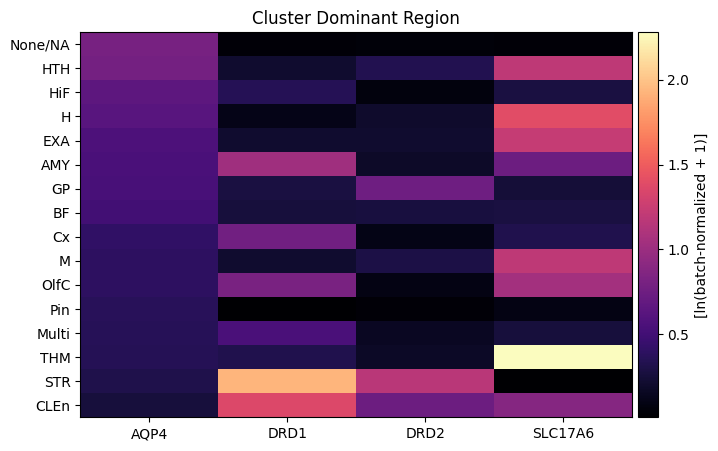

In [20]:
gene_names = cell_metadata_with_genes.columns[
    cell_metadata_with_genes.columns.isin(gene_names)
].to_numpy()
for level in ['Group', 'Cluster']:
    agg = aggregate_by_metadata(cell_metadata_with_genes, gene_names, f'{level}_dominant_region', sort=True)
    plot_heatmap(agg, 8, 5)
    plt.title(f'{level} Dominant Region')
    plt.show()

### Visualize gene expression for selected genes by the HMBA-Subcortex taxonomy.

Below we average the expression of our selected genes across the neurotransmitter at the Group and Cluster level.

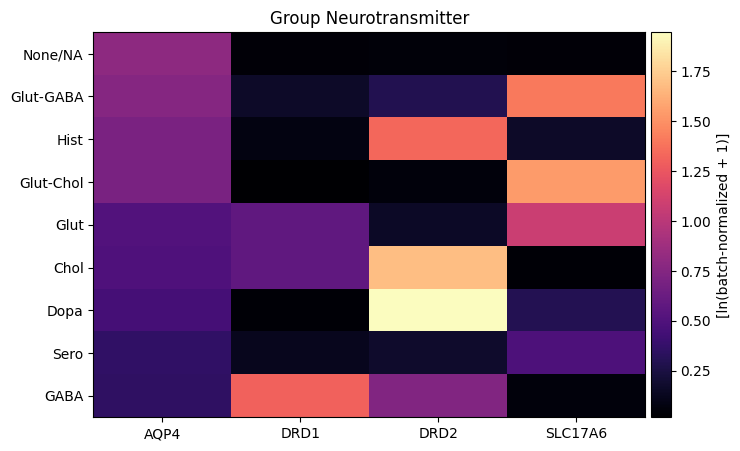

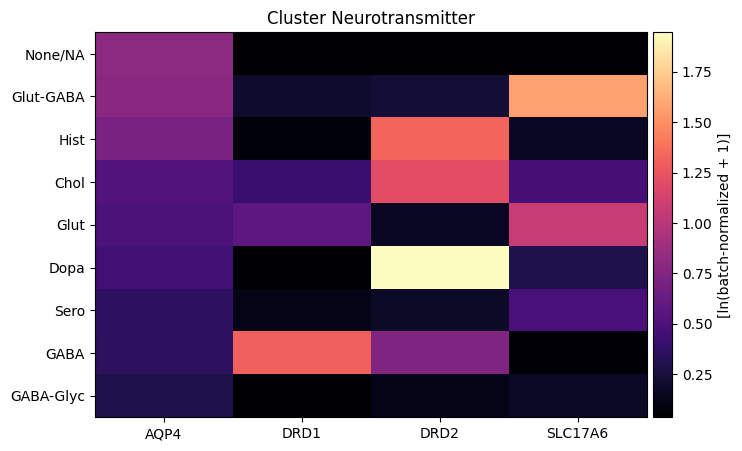

In [21]:
gene_names = cell_metadata_with_genes.columns[
    cell_metadata_with_genes.columns.isin(gene_names)
].to_numpy()
for level in ['Group', 'Cluster']:
    agg = aggregate_by_metadata(cell_metadata_with_genes, gene_names, f'{level}_neurotransmitter', sort=True)
    plot_heatmap(agg, 8, 5)
    plt.title(f'{level} Neurotransmitter')
    plt.show()

To learn more about the spatial data see the [HBMA-Subcortex Spatial Slabs and Taxonomy notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_spatial_slabs_and_taxonomy.html).

To learn more about the taxonomy used in this notebook and the data it is derived from, see the [HMBA-Subcortex Clustering Analysis and Taxonomy notebook](https://alleninstitute.github.io/abc_atlas_access/notebooks/hmba_subcortex_clustering_analysis_and_annotation.html).